# Review 3 — Three-Model Comparison and Historical Race Replay

**Deep Learning-Based Virtual Race Engineer for Real-Time Formula 1 Strategy Optimization**

---

This notebook puts the three models side by side on the **held-out 2024 season** — 24 races and
22,228 driver-laps that no model saw during training, validation or threshold selection — and then
replays those races to compare the models' calls against the strategy decisions real race
engineers actually made.

## 1. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import keras
from IPython.display import Image, display

from src import config
from src.evaluation import metrics as M, plots

config.ensure_dirs()
config.set_seed()
plots.apply_style()
print("keras", keras.__version__, "| project", config.PROJECT_ROOT)

keras 3.12.0 | project C:\E\Project\Deep Learning


## 2. Recovering each model's predictions

The per-model metrics files record confusion matrices but not the probabilities themselves, so the
combined curves cannot be drawn from them.

`src/evaluation/predict.py` reloads each model **from the checkpoint its training run saved**
rather than retraining — retraining risks small numerical drift and would leave these figures
disagreeing with numbers already reported. It then recomputes each model's metrics from the
recovered probabilities and **aborts** if they differ from the stored run by more than 1e-6.

In [2]:
from src.evaluation import compare as C
from src.evaluation.compare import ORDER, SHORT

y_test, models = C.load_all()
print(f"test set: {len(y_test):,} driver-laps, {100*y_test.mean():.2f}% positive\n")
for k in ORDER:
    m = models[k]["metrics"]
    print(f"  {SHORT[k]:<28} {m['n_parameters']:>7,} params   "
          f"ROC-AUC {m['test']['roc_auc']:.4f}   PR-AUC {m['test']['pr_auc']:.4f}")

test set: 22,228 driver-laps, 8.52% positive

  Model 1 — Bi-LSTM            104,769 params   ROC-AUC 0.8058   PR-AUC 0.3232
  Model 2 — CNN–BiLSTM           8,881 params   ROC-AUC 0.7717   PR-AUC 0.3055
  Model 3 — MTL + attention     48,394 params   ROC-AUC 0.7555   PR-AUC 0.2650


## 3. The comparison table

In [3]:
table = C.build_table(y_test, models)
table.set_index("model").round(4)

,params,train_s,ms_per_lap,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,,,,,
Never-pit baseline,NaN,NaN,NaN,0.500,0.9148,0.5000,0.0000,0.0000,0.0000,0.5000,0.0852
Model 1 — Bi-LSTM,104769.0,53.04,0.0610,0.779,0.8642,0.6713,0.2982,0.4388,0.3551,0.8058,0.3232
Model 2 — CNN–BiLSTM,8881.0,49.20,0.0479,0.796,0.8404,0.6760,0.2613,0.4778,0.3378,0.7717,0.3055
Model 3 — MTL + attention,48394.0,61.83,0.0271,0.708,0.8177,0.6732,0.2334,0.4989,0.3181,0.7555,0.2650


**Read the baseline row first.** Predicting "no pit" on every lap scores 0.9148 accuracy and
exactly zero on precision, recall and F1. That row is why accuracy cannot be the headline metric
for this problem.

## 4. Accuracy and loss graphs — all three models

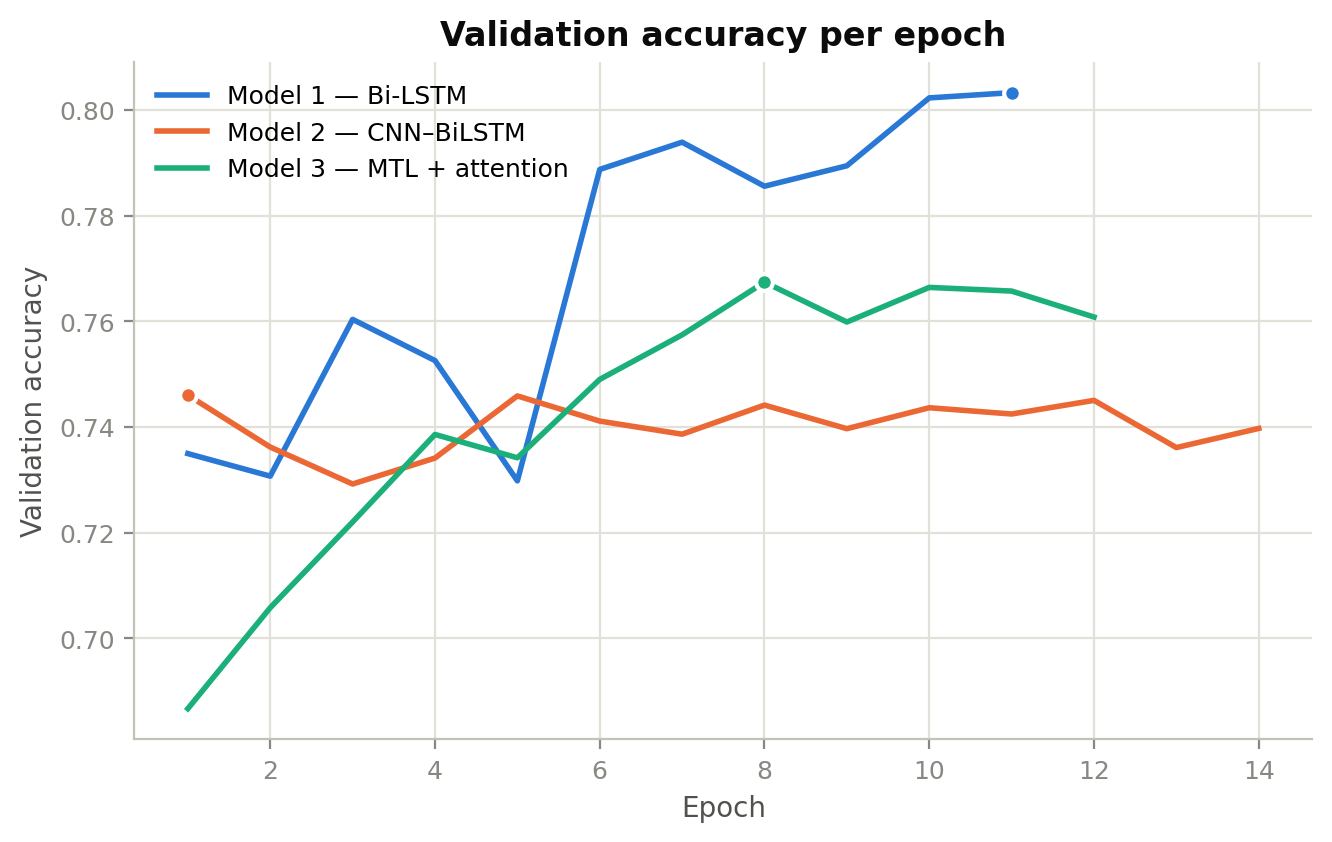

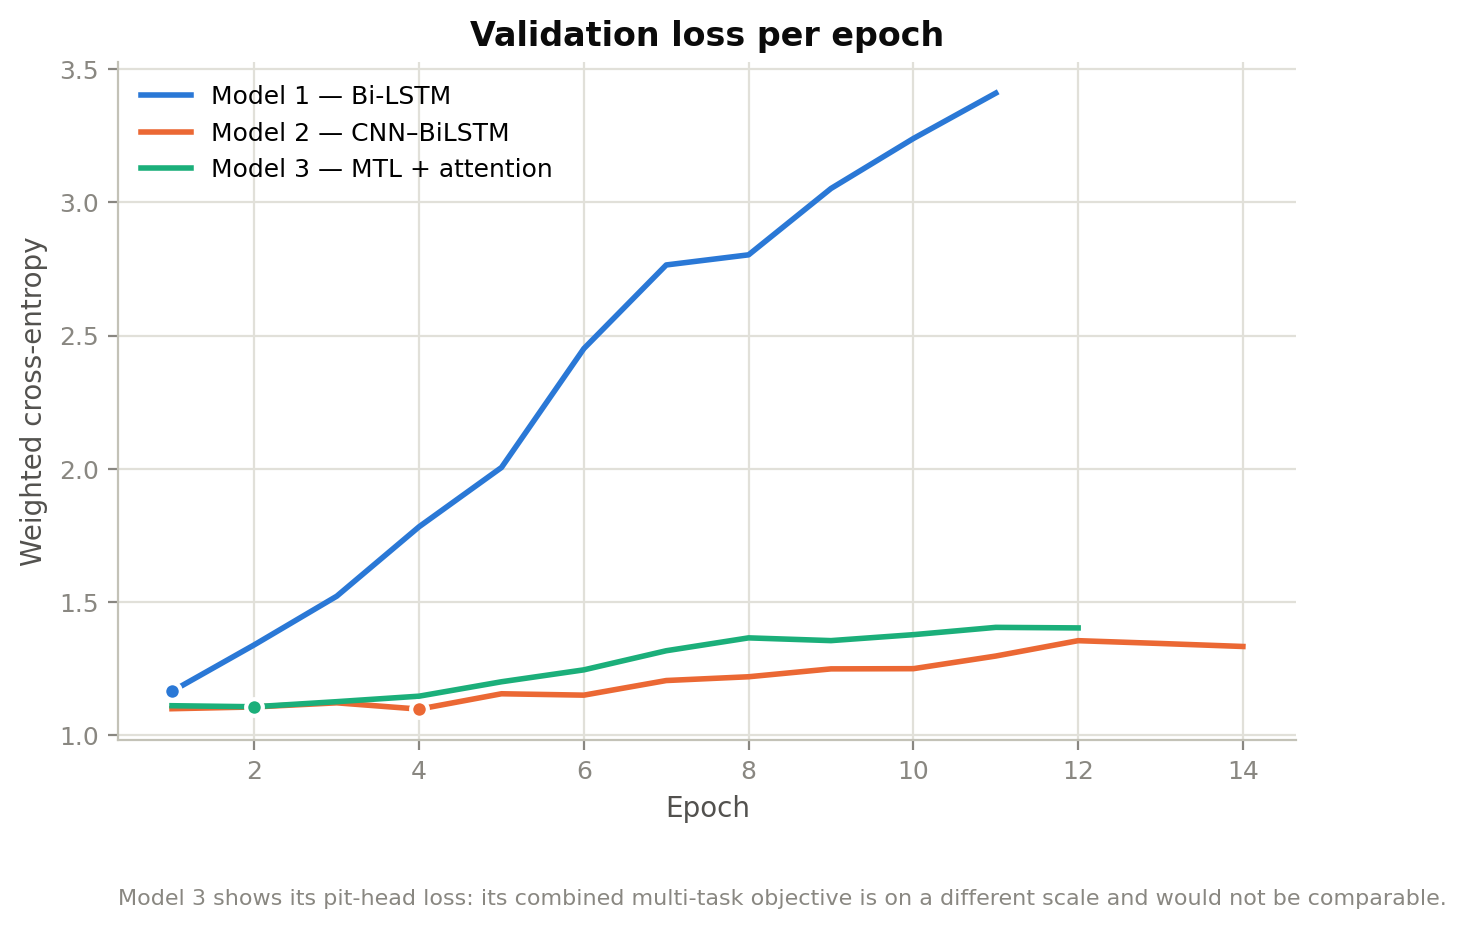

In [4]:
display(Image(C.plot_curves(models, "accuracy", "Validation accuracy per epoch",
                            "Validation accuracy", "accuracy")))
display(Image(C.plot_curves(models, "loss", "Validation loss per epoch",
                            "Weighted cross-entropy", "loss",
                            note="Model 3 shows its pit-head loss: its combined multi-task "
                                 "objective is on a different scale and would not be comparable.")))

Model 3's **pit-head** loss is plotted, not its total. Models 1 and 2 minimise weighted binary
cross-entropy; Model 3 minimises a combined four-head objective on a different scale, so
overlaying the totals would compare quantities that are not the same thing.

## 5. Confusion matrices — all three models

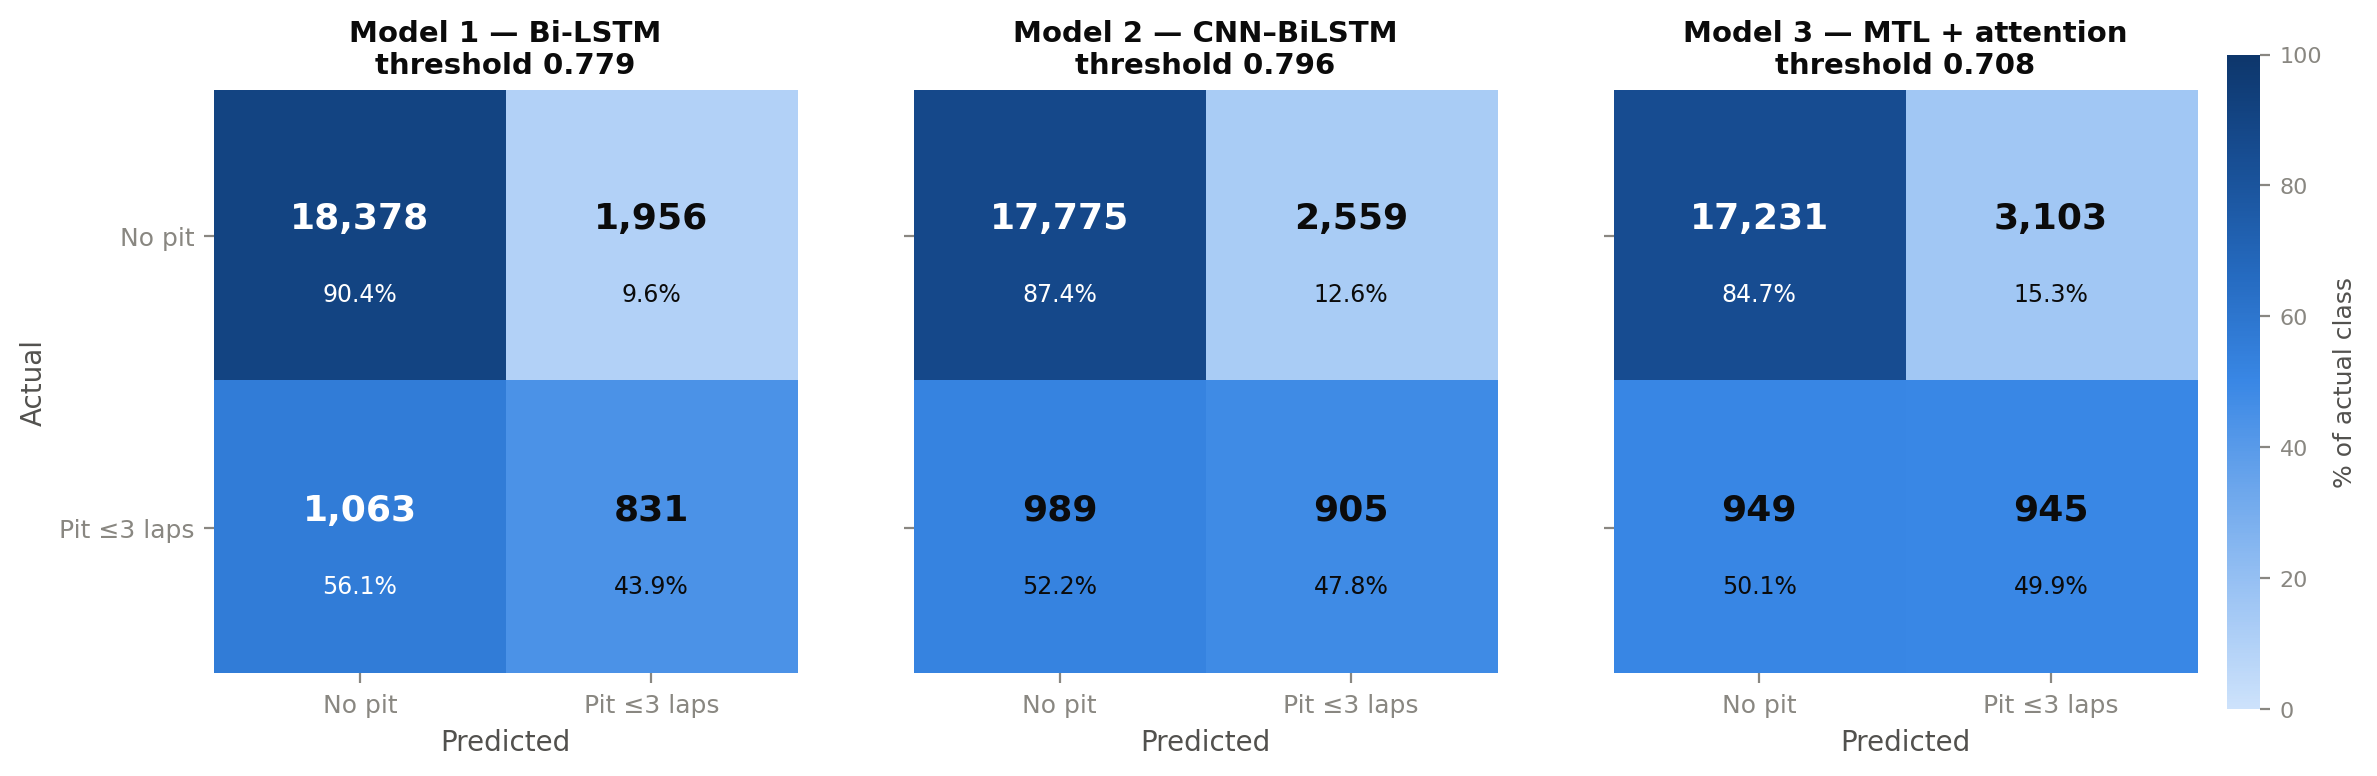

In [5]:
display(Image(C.plot_confusions(models)))

Each cell shows the raw count and that count as a share of its true class. The **row
percentages** are what matter: in absolute terms the "No pit" row dwarfs everything else.

* **Bottom-right** — stops correctly anticipated, the number the project exists to raise.
* **Bottom-left** — missed stops; in a real race these are the expensive errors.
* **Top-right** — false alarms; comparatively cheap, since a warned strategist who does not stop
  loses nothing.

## 6. ROC and precision-recall curves

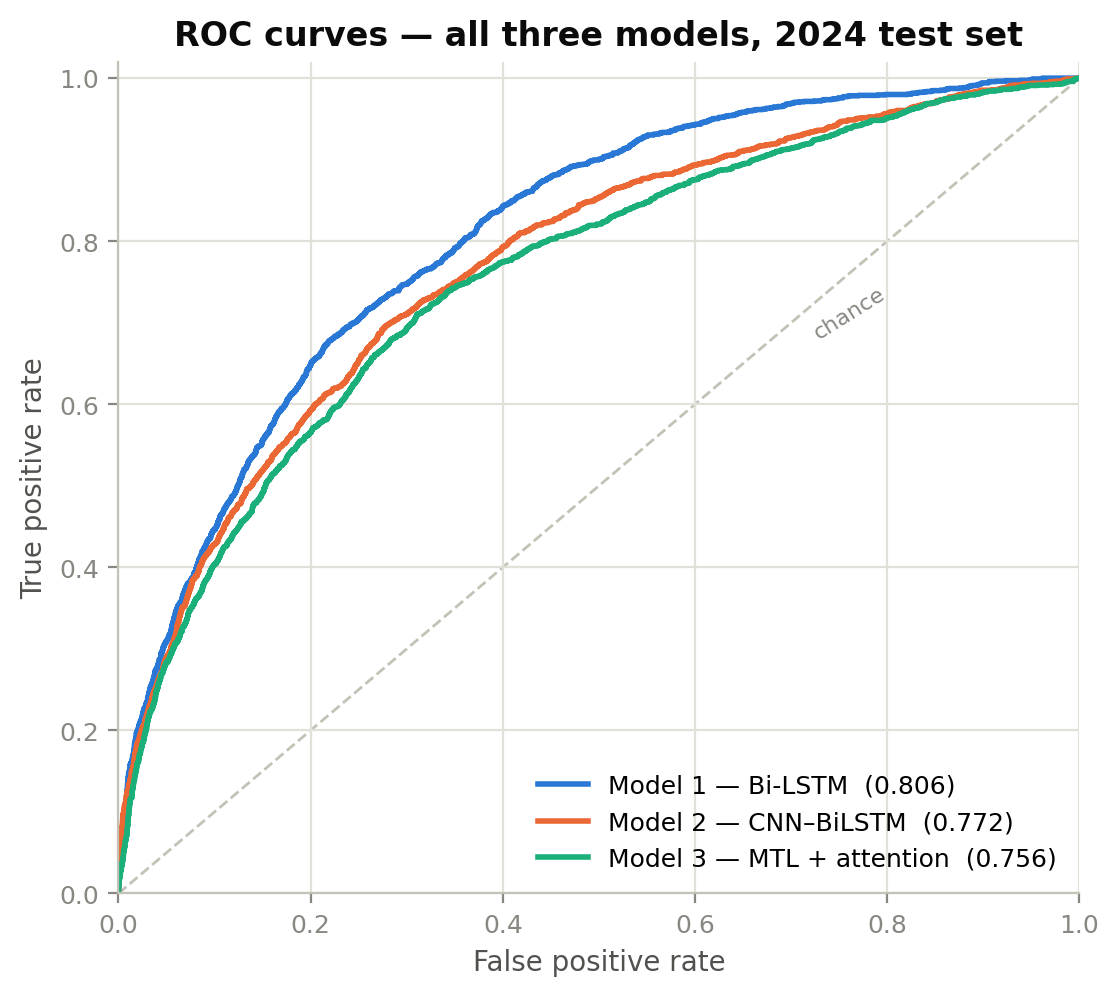

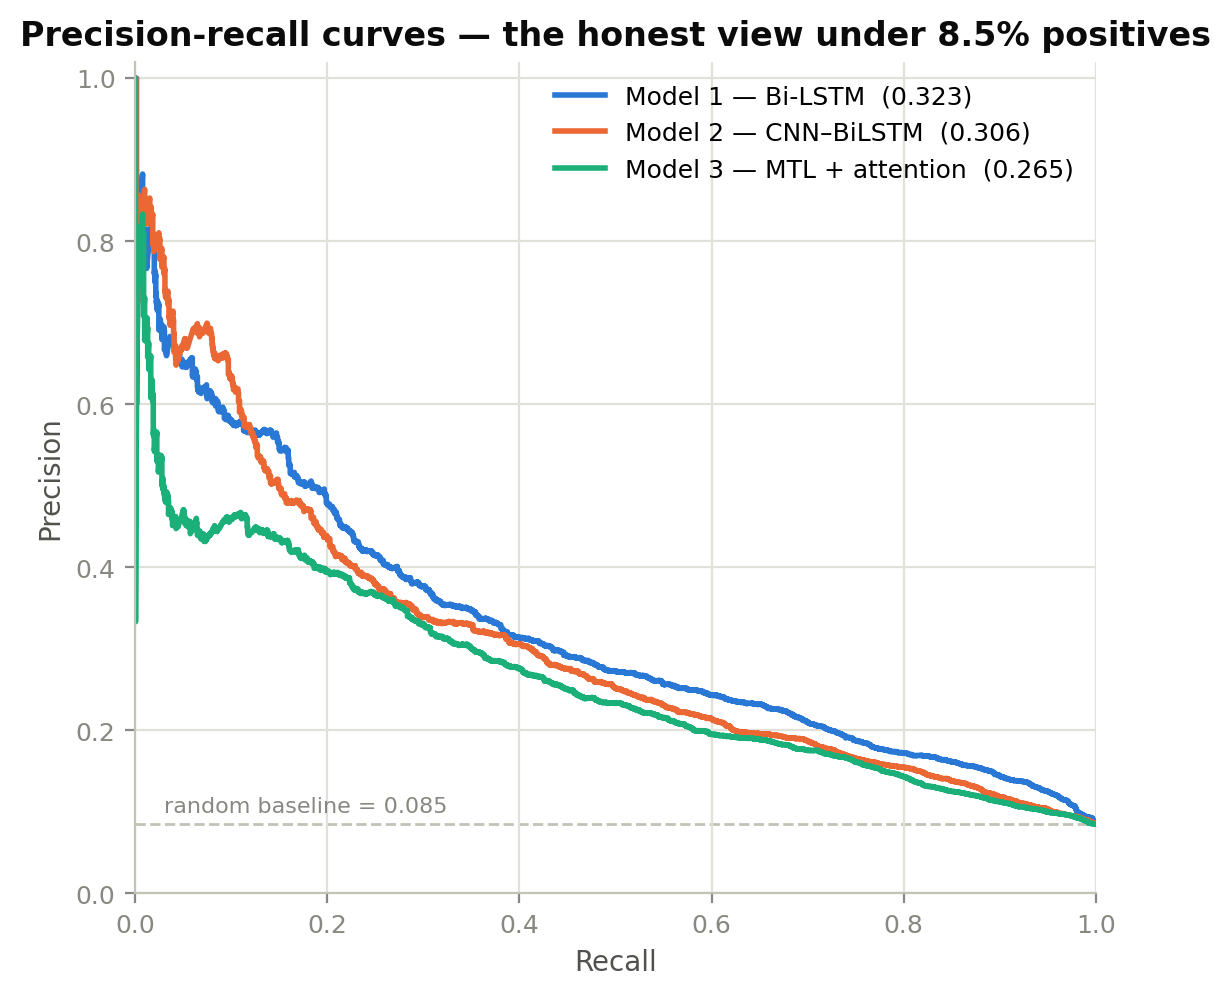

In [6]:
display(Image(C.plot_roc(y_test, models)))
display(Image(C.plot_pr(y_test, models)))

The **precision-recall curve is the honest one** on an imbalanced problem: its baseline is the
positive rate (0.085), not a diagonal. ROC's diagonal flatters imbalanced problems.

## 7. "Most efficient" is a two-axis claim

The system's premise is real-time operation, so size and latency are part of the claim. On that
axis the ranking inverts.

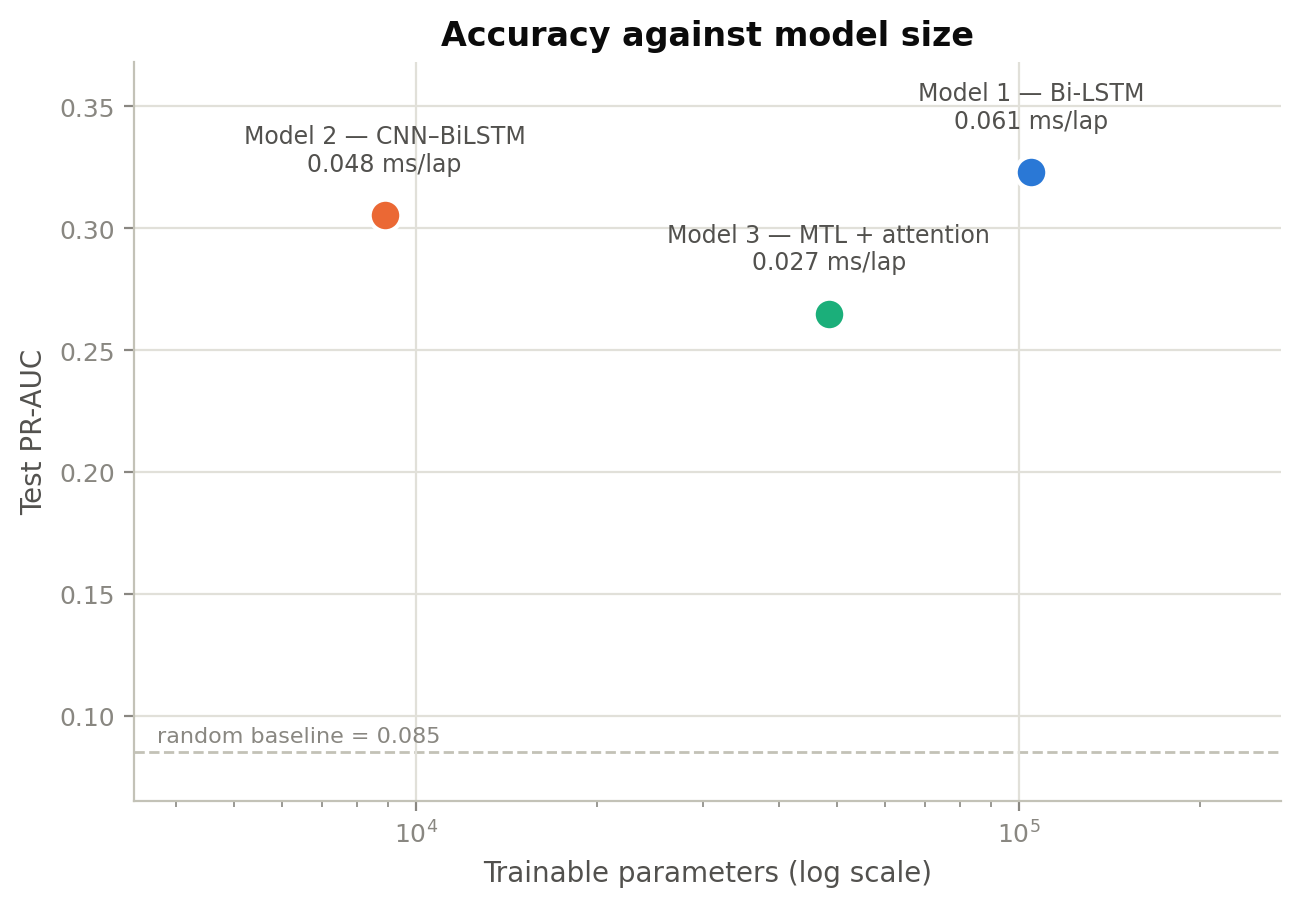

,params,train_s,ms_per_lap,test PR-AUC
model,,,,
Model 1 — Bi-LSTM,104769,53.04,0.0610,0.3232
Model 2 — CNN–BiLSTM,8881,49.20,0.0479,0.3055
Model 3 — MTL + attention,48394,61.83,0.0271,0.2650


In [7]:
display(Image(C.plot_efficiency(models)))
pd.DataFrame([{"model": SHORT[k],
               "params": models[k]["metrics"]["n_parameters"],
               "train_s": models[k]["metrics"]["train_time_s"],
               "ms_per_lap": models[k]["metrics"]["inference_ms_per_sample"],
               "test PR-AUC": round(models[k]["metrics"]["test"]["pr_auc"], 4)} for k in ORDER]
            ).set_index("model")

## 8. Is a deep sequence model justified at all?

A deep model should be justified, not assumed. Two classical models trained on **exactly the same
tensors**, scored exactly the same way.

This comparison is not decoration — it is the diagnostic that caught a serious bug during
development. An early version of Model 1 scored ROC-AUC 0.495, and it was these baselines reaching
0.82 and 0.85 on identical data that proved the fault lay in the network rather than the
features.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

seq = np.load(config.DATA_PROCESSED / "sequences.npz")
Xtr, ytr, Xte = seq["X_train"], seq["y_train"], seq["X_test"]

rows = [{"model": "Random (base rate)", "ROC-AUC": 0.5, "PR-AUC": float(y_test.mean())}]

lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr[:, -1, :], ytr)
p = lr.predict_proba(Xte[:, -1, :])[:, 1]
rows.append({"model": "Logistic regression (final lap)",
             "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})

gb = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced",
                                    random_state=config.RANDOM_SEED)
gb.fit(Xtr.reshape(len(Xtr), -1), ytr)
p = gb.predict_proba(Xte.reshape(len(Xte), -1))[:, 1]
rows.append({"model": "Gradient boosting (flat window)",
             "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})

for k in ORDER:
    m = models[k]["metrics"]["test"]
    rows.append({"model": SHORT[k], "ROC-AUC": m["roc_auc"], "PR-AUC": m["pr_auc"]})

pd.DataFrame(rows).set_index("model").round(4)

,ROC-AUC,PR-AUC
model,,
Random (base rate),0.5000,0.0852
Logistic regression (final lap),0.8024,0.3084
Gradient boosting (flat window),0.8534,0.3907
Model 1 — Bi-LSTM,0.8058,0.3232
Model 2 — CNN–BiLSTM,0.7717,0.3055
Model 3 — MTL + attention,0.7555,0.2650


**Answer, stated honestly: not yet.** Gradient boosting on the flattened window still
outperforms all three deep models. The sequence architectures are not yet earning their complexity
on this dataset — and across eighteen configurations spanning 8.8k to 162k parameters, validation
PR-AUC never left the 0.27–0.33 band. **The ceiling is the data, not the model.**

## 9. Historical race replay — AI calls vs. the pit wall

This is the project's eighth objective: evaluating the model's recommendations against the
decisions real race engineers made.

Per-lap metrics answer *"how often is the model right about a lap"*. A strategist asks something
different: **of the stops that happened, how many did we see coming, and how early?** So the
replay scores **per stop**.

Consecutive firing laps before one stop count as a **single alarm**, not three — counting each lap
separately would badly overstate the noise, because the label itself spans a three-lap window.

In [9]:
from src.evaluation import replay as R

test, horizon = R.load_test_frame()
summary = R.season_summary(test, horizon)
summary.set_index("model")

,threshold,stops_in_season,anticipated,anticipated_pct,median_lead_laps,false_alarms,false_alarms_per_driver_race
model,,,,,,,
Model 1 — Bi-LSTM,0.779,644,314,48.8,3.0,66,0.14
Model 2 — CNN–BiLSTM,0.796,644,356,55.3,3.0,101,0.22
Model 3 — MTL + attention,0.708,644,355,55.1,3.0,123,0.27


### The operational ranking is not the per-lap ranking

Model 1 leads on PR-AUC but anticipates the **fewest** stops: its higher tuned threshold makes it
the most conservative, which buys the lowest false-alarm rate. Model 2 catches 42 more stops across
the season for one extra false alarm roughly every twelve driver-races.

Which is preferable is a strategy call, not a modelling one — and that the two views disagree is
exactly what the replay exists to expose.

In absolute terms the rate is usable: about **three laps of warning on more than half of all real
stops**, with a spurious warning only once every four to seven driver-races.

### One driver's race, lap by lap

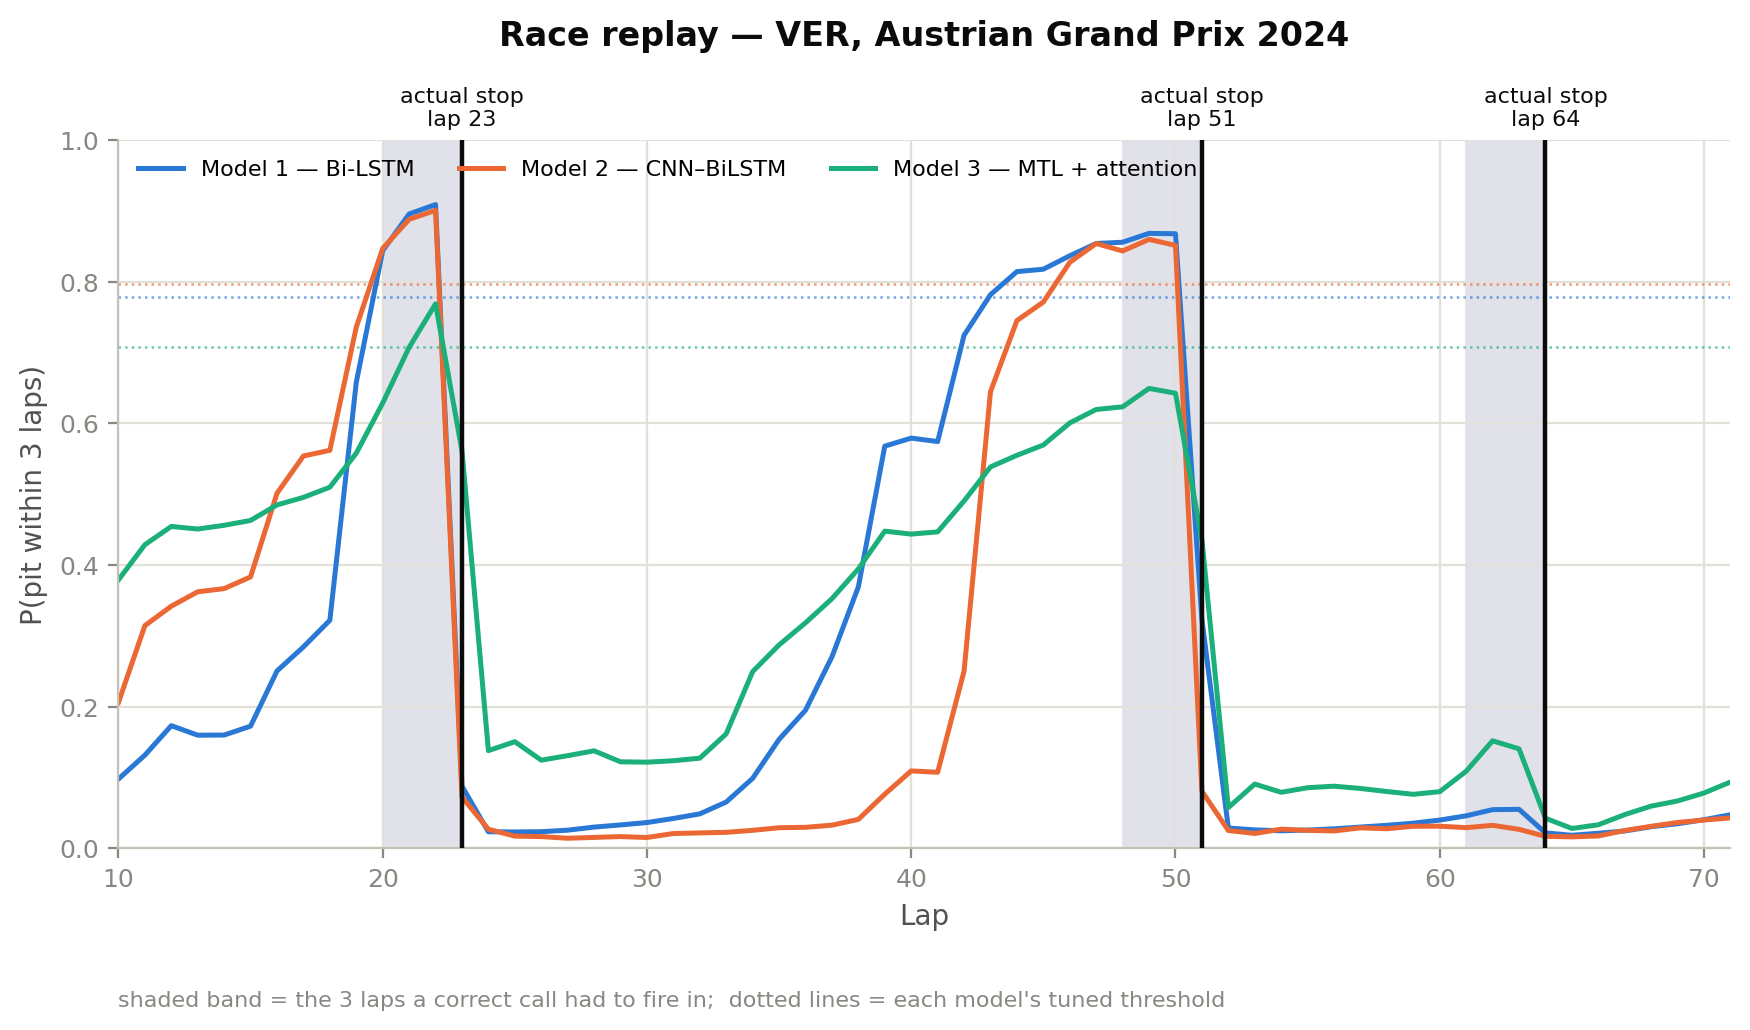


Team pitted VER on lap 23
   Model 1 — Bi-LSTM            flagged lap 20, 3 lap(s) early
   Model 2 — CNN–BiLSTM         flagged lap 20, 3 lap(s) early
   Model 3 — MTL + attention    flagged lap 22, 1 lap(s) early

Team pitted VER on lap 51
   Model 1 — Bi-LSTM            flagged lap 48, 3 lap(s) early
   Model 2 — CNN–BiLSTM         flagged lap 48, 3 lap(s) early
   Model 3 — MTL + attention    no call

Team pitted VER on lap 64
   Model 1 — Bi-LSTM            no call
   Model 2 — CNN–BiLSTM         no call
   Model 3 — MTL + attention    no call


In [10]:
race, driver = "2024_11", "VER"
event = test.loc[test["RaceId"] == race, "EventName"].iloc[0]
display(Image(R.plot_driver_replay(test, race, driver, horizon, event)))

d = test[(test["RaceId"] == race) & (test["Driver"] == driver)].sort_values("LapNumber")
for stop in R.actual_stop_laps(d, horizon):
    print(f"\nTeam pitted {driver} on lap {int(stop)}")
    for k in ORDER:
        thr = test.attrs["thresholds"][k]
        fired = [int(l) for l, p in zip(d["LapNumber"], d[k])
                 if stop - horizon <= l <= stop - 1 and p >= thr]
        print(f"   {SHORT[k]:<28} " + (f"flagged lap {fired[0]}, {int(stop)-fired[0]} lap(s) early"
                                        if fired else "no call"))

### The whole field at once

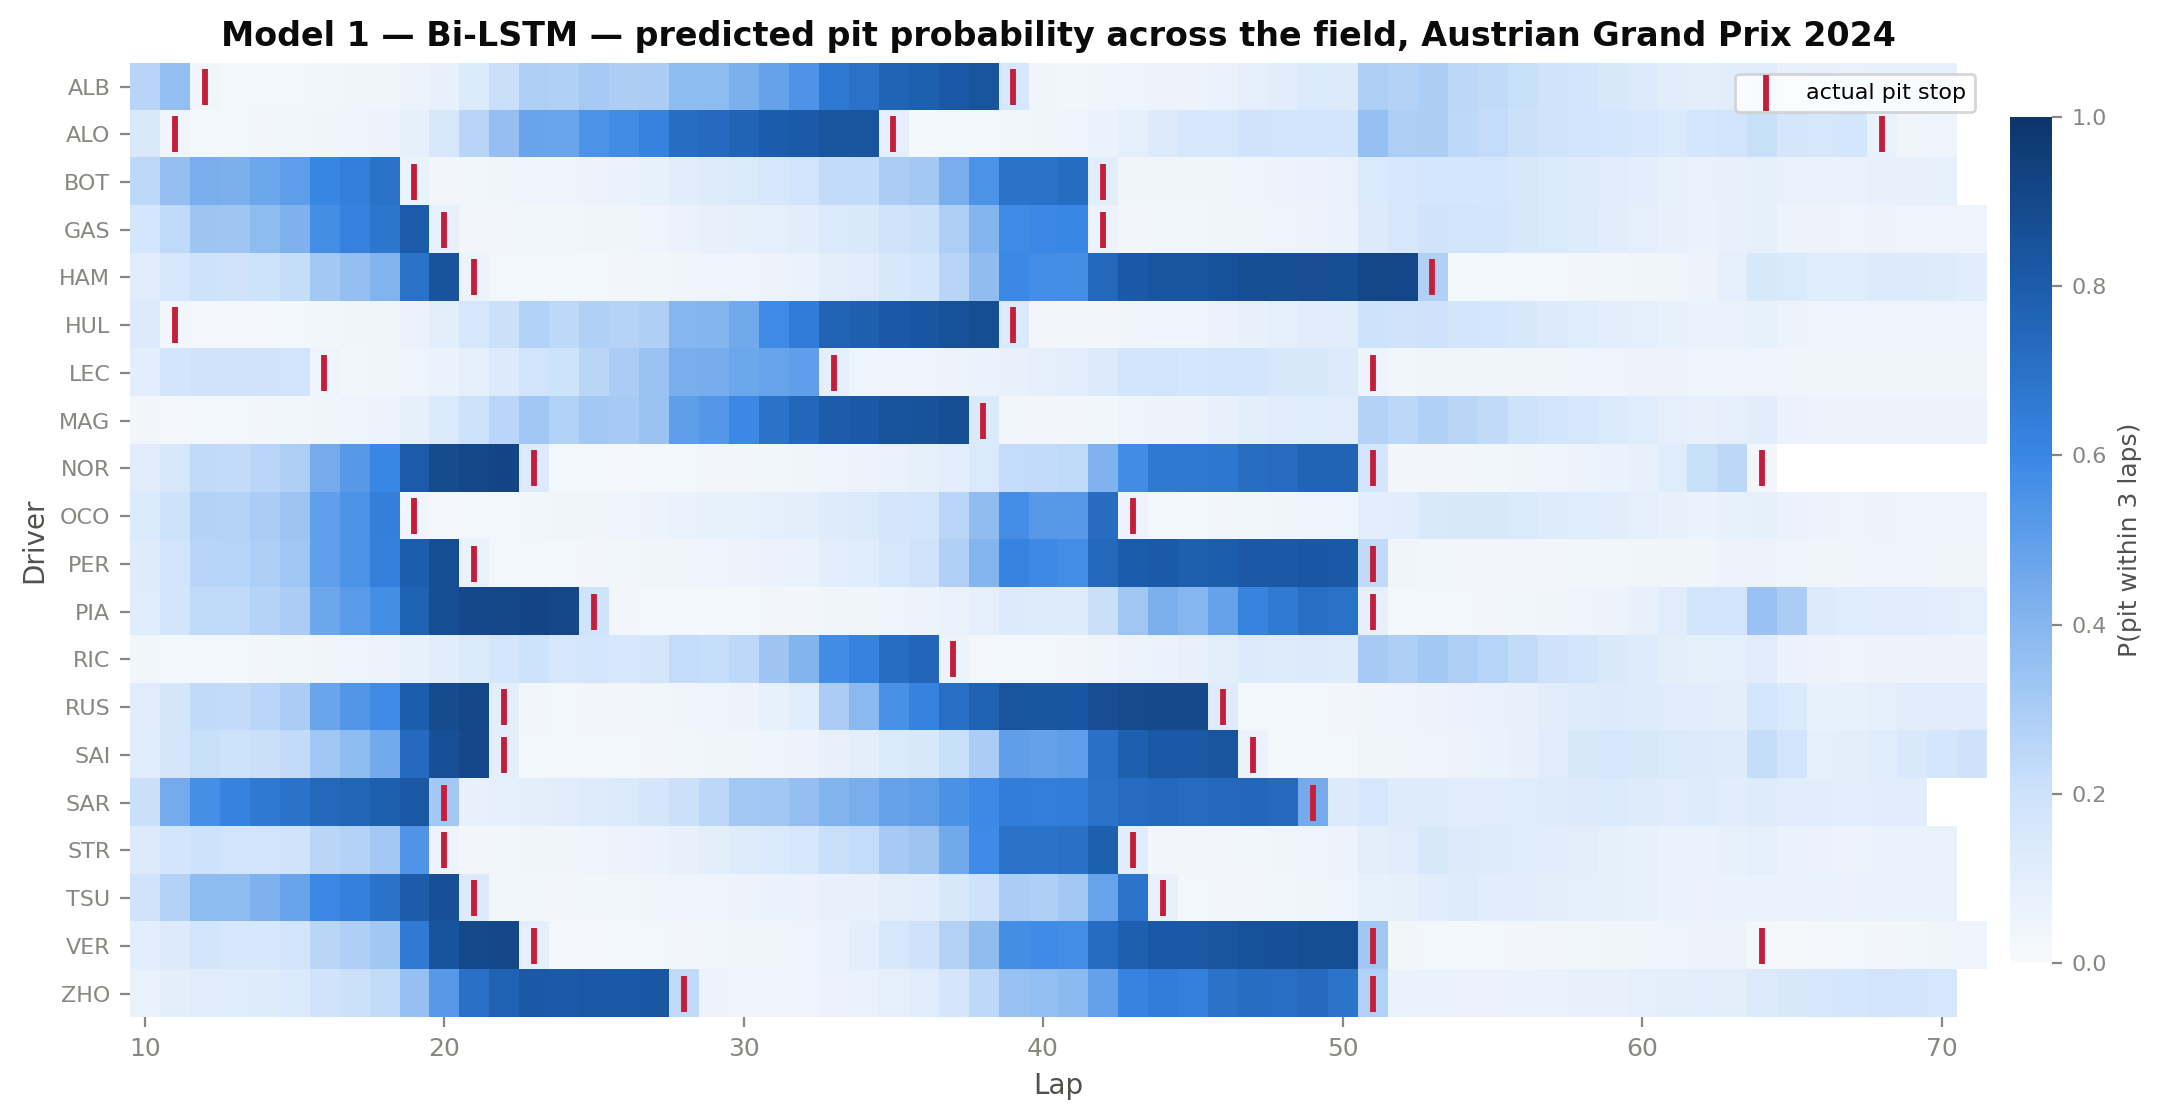

In [11]:
display(Image(R.plot_race_grid(test, race, ORDER[0], horizon, event)))

Probability builds through every driver's stint and collapses the moment they pit. The red
marks are the actual stops.

An animated version of this figure (`reports/figures/replay_animated_2024_11.gif`) and a fully
interactive page (`reports/demo/race_engineer_demo.html`) are also in the repository.

## 10. Conclusions

1. **All three models beat chance decisively** — PR-AUC 0.265 to 0.323 against a 0.085 base rate.
2. **The simplest architecture wins on accuracy.** The plain Bi-LSTM takes both AUCs; neither
   convolutions nor attention improved on it.
3. **Cross-driver attention does not help.** A 2×2 ablation shows it costs performance in both
   conditions — a clean negative result about the project's own proposed mechanism.
4. **Per-lap and operational rankings disagree.** Model 1 leads on PR-AUC yet anticipates the
   fewest real stops.
5. **Model 2 is the efficiency winner** — 12× smaller than Model 1 for 0.017 less PR-AUC.
6. **The ceiling is the data, not the model.** Eighteen configurations across three architectures
   all land in the same narrow band.

### Limitations

Public telemetry is coarser than a team's own; the effective sample size is modest because windows
overlap and only 89 races are usable; each configuration was run with a single seed, so
differences of a few thousandths in PR-AUC should not be read as meaningful; and the cause of a
stop — a planned stop versus a puncture or a safety car — is not modelled.